## UTS Naive Bayes - KNN
### Sheila Fatiha Az Zahra 202431040

In [55]:
# 202431040

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

### Load Dataset

In [26]:
# 202431040

data = pd.read_csv('04_bank_customers.csv', sep=';')
data

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


### Memahami struktur dataset

In [27]:
# 202431040
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [28]:
# 202431040
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [29]:
# 202431040
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


### Pemeriksaan missing value dan duplikasi

In [4]:
# 202431040

print("Jumlah Missing Value:")
print(df.isnull().sum())

print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

Jumlah Missing Value:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Jumlah Data Duplikat:
0


In [47]:
# 202431040
numerical_features = data.select_dtypes(include=np.number).columns.tolist()
print("Jumlah fitur numerik:", len(numerical_features))
print("Daftar fitur numerik:", numerical_features)
display(data[numerical_features].head())

Jumlah fitur numerik: 7
Daftar fitur numerik: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


,age,balance,day,duration,campaign,pdays,previous
0,58,2143,5,261,1,-1,0
1,44,29,5,151,1,-1,0
2,33,2,5,76,1,-1,0
3,47,1506,5,92,1,-1,0
4,33,1,5,198,1,-1,0


In [ ]:
### identifikasi fitur kategorikal

In [48]:
# 202431040
categorical_features = data.select_dtypes(exclude=np.number).columns.tolist()
print("Jumlah fitur kategorikal:", len(categorical_features))
print("Daftar fitur kategorikal:", categorical_features)
display(data[categorical_features].head())

Jumlah fitur kategorikal: 10
Daftar fitur kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


,job,marital,education,default,housing,loan,contact,month,poutcome,y
0,management,married,tertiary,no,yes,no,unknown,may,unknown,no
1,technician,single,secondary,no,yes,no,unknown,may,unknown,no
2,entrepreneur,married,secondary,no,yes,yes,unknown,may,unknown,no
3,blue-collar,married,unknown,no,yes,no,unknown,may,unknown,no
4,unknown,single,unknown,no,no,no,unknown,may,unknown,no


In [50]:
# 202431040
for col in categorical_features:
    print(f"\nKolom: {col}")
    print(data[col].unique())


Kolom: job
['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']

Kolom: marital
['married' 'single' 'divorced']

Kolom: education
['tertiary' 'secondary' 'unknown' 'primary']

Kolom: default
['no' 'yes']

Kolom: housing
['yes' 'no']

Kolom: loan
['no' 'yes']

Kolom: contact
['unknown' 'cellular' 'telephone']

Kolom: month
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']

Kolom: poutcome
['unknown' 'failure' 'other' 'success']

Kolom: y
['no' 'yes']


### EDA Distrubusi Target

no     39922
yes     5289
Name: y, dtype: int64
no     88.3
yes    11.7
Name: y, dtype: float64


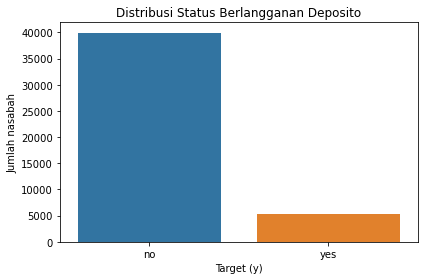

In [51]:
# 202431040
print(data['y'].value_counts())
print((data['y'].value_counts(normalize=True) * 100).round(2))

sns.countplot(data=data, x='y')
plt.title('Distribusi Status Berlangganan Deposito')
plt.xlabel('Target (y)')
plt.ylabel('Jumlah nasabah')
plt.tight_layout()
plt.show()

### EDA Distribusi umur

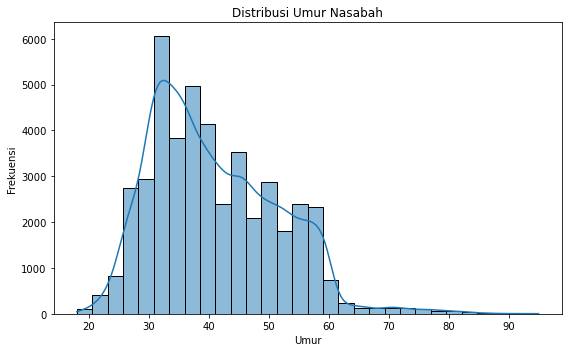

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

In [52]:
# 202431040
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='age', bins=30, kde=True)
plt.title('Distribusi Umur Nasabah')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()
display(data['age'].describe())

### Mentukan fitur dan target Naive Bayes

In [53]:
# 202431040
X = data.drop(columns=['y', 'duration'])
y = data['y'].map({'no': 0, 'yes': 1})

print("Fitur prediktor:", X.columns.tolist())
print("\nDistribusi target:")
print(y.value_counts())

Fitur prediktor: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Distribusi target:
0    39922
1     5289
Name: y, dtype: int64


### Membagi data Trainnig dan Testing

In [57]:
# 202431040
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (36168, 15)
X_test : (9043, 15)
y_train: (36168,)
y_test : (9043,)


### Preprocessing Data

In [58]:
# 202431040
try:
    encoder_nb = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder_nb = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_nb = ColumnTransformer(
    transformers=[
        ('numerik', StandardScaler(), numerical_features[:-0] if False else X.select_dtypes(include=np.number).columns.tolist()),
        ('kategori', encoder_nb, X.select_dtypes(exclude=np.number).columns.tolist())
    ]
)

print("Preprocessing siap digunakan.")

Preprocessing siap digunakan.


### Training Model Gaussian Naive Bayes

In [61]:
# 202431040
model_nb = Pipeline(steps=[
    ('preprocessing', preprocessor_nb),
    ('classifier', GaussianNB())
])

model_nb.fit(X_train, y_train)
print("Model Gaussian Naive Bayes berhasil dilatih.")

Model Gaussian Naive Bayes berhasil dilatih.


### Prediksi Data Testing Naive Bayes

In [62]:
# 202431040
y_pred_nb = model_nb.predict(X_test)
print("Lima belas hasil prediksi pertama:", y_pred_nb[:15])

Lima belas hasil prediksi pertama: [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]


### Evaluasi Naive Bayes

In [63]:
# 202431040
print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_nb, zero_division=0))
print("F1-Score :", f1_score(y_test, y_pred_nb, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_nb,
    labels=[0, 1], target_names=['No', 'Yes'],
    zero_division=0
))

Accuracy : 0.8451841203140551
Precision: 0.37084592145015105
Recall   : 0.46408317580340264
F1-Score : 0.4122586062132662

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.90      0.91      7985
         Yes       0.37      0.46      0.41      1058

    accuracy                           0.85      9043
   macro avg       0.65      0.68      0.66      9043
weighted avg       0.86      0.85      0.85      9043



### Confusion Matrix Naive Bayes

Confusion Matrix Naive Bayes:
[[7152  833]
 [ 567  491]]
TN=7152, FP=833, FN=567, TP=491


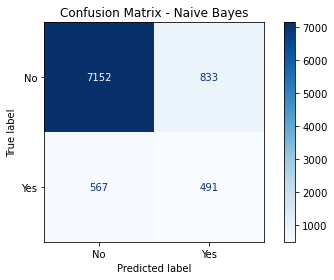

In [64]:
# 202431040
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=[0, 1])
print("Confusion Matrix Naive Bayes:")
print(cm_nb)

tn, fp, fn, tp = cm_nb.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=['No', 'Yes']
).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Naive Bayes')
plt.tight_layout()
plt.show()

## K-Nearest Neighbors (KNN)

In [38]:
# 202431040
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0


### Menyiapkan fitur dan target KNN

In [65]:
# 202431040
X_knn = data.drop(columns=['y', 'duration'])
y_knn = data['y'].map({'no': 0, 'yes': 1})

print("Fitur KNN:", X_knn.columns.tolist())
print("Distribusi target:")
print(y_knn.value_counts())

Fitur KNN: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
Distribusi target:
0    39922
1     5289
Name: y, dtype: int64


### Membagi data Training dan Testing KNN

In [66]:
# 202431040
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X_knn, y_knn,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_knn
)

print("X_train KNN:", X_train_knn.shape)
print("X_test KNN :", X_test_knn.shape)

X_train KNN: (36168, 15)
X_test KNN : (9043, 15)


### Preprocessing KNN (Encoding dan Standarisasi)

In [67]:
# 202431040
try:
    encoder_knn = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder_knn = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor_knn = ColumnTransformer(
    transformers=[
        ('numerik', StandardScaler(),
         X_knn.select_dtypes(include=np.number).columns.tolist()),
        ('kategori', encoder_knn,
         X_knn.select_dtypes(exclude=np.number).columns.tolist())
    ]
)

print("Preprocessing KNN siap digunakan.")

Preprocessing KNN siap digunakan.


### Training Model KNN dengan k=5

In [68]:
# 202431040
model_knn = Pipeline(steps=[
    ('preprocessing', preprocessor_knn),
    ('classifier', KNeighborsClassifier(n_neighbors=5, weights='uniform'))
])

model_knn.fit(X_train_knn, y_train_knn)
print("Model KNN dengan k=5 berhasil dilatih.")

Model KNN dengan k=5 berhasil dilatih.


### Prediksi Data Testing KNN

In [69]:
# 202431040
y_pred_knn = model_knn.predict(X_test_knn)
print("Lima belas hasil prediksi pertama:", y_pred_knn[:15])

Lima belas hasil prediksi pertama: [0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]


### Evaluasi Model KNN

In [70]:
# 202431040
print("Accuracy :", accuracy_score(y_test_knn, y_pred_knn))
print("Precision:", precision_score(y_test_knn, y_pred_knn, zero_division=0))
print("Recall   :", recall_score(y_test_knn, y_pred_knn, zero_division=0))
print("F1-Score :", f1_score(y_test_knn, y_pred_knn, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test_knn, y_pred_knn,
    labels=[0, 1], target_names=['No', 'Yes'],
    zero_division=0
))

Accuracy : 0.8874267389140772
Precision: 0.5529100529100529
Recall   : 0.19754253308128544
F1-Score : 0.29108635097493035

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.98      0.94      7985
         Yes       0.55      0.20      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.73      0.59      0.61      9043
weighted avg       0.86      0.89      0.86      9043



### Confusion Matrix KNN

Confusion Matrix KNN:
[[7816  169]
 [ 849  209]]
TN=7816, FP=169, FN=849, TP=209


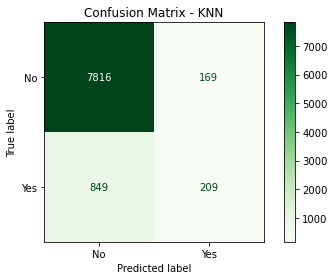

In [71]:
# 202431040
cm_knn = confusion_matrix(y_test_knn, y_pred_knn, labels=[0, 1])
print("Confusion Matrix KNN:")
print(cm_knn)

tn, fp, fn, tp = cm_knn.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=['No', 'Yes']
).plot(cmap='Greens', values_format='d')
plt.title('Confusion Matrix - KNN')
plt.tight_layout()
plt.show()

### Menguji beberapa Nilai k pada KNN

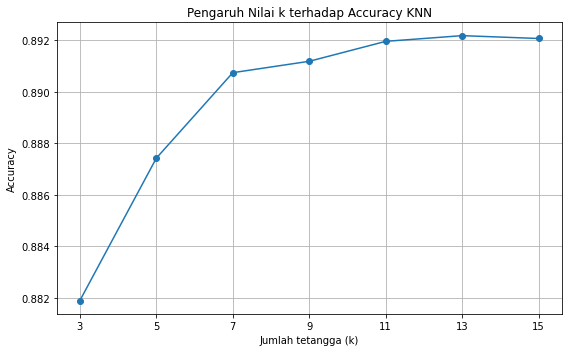

Accuracy setiap k: {3: 0.8818976003538649, 5: 0.8874267389140772, 7: 0.8907442220502045, 9: 0.8911865531350216, 11: 0.8919606325334513, 13: 0.8921817980758597, 15: 0.8920712153046555}


In [72]:
# 202431040

# Data ditransformasikan satu kali; scaler/encoder hanya fit pada training.
X_train_knn_transformed = preprocessor_knn.fit_transform(X_train_knn)
X_test_knn_transformed = preprocessor_knn.transform(X_test_knn)

k_values = range(3, 16, 2)
accuracies = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_knn_transformed, y_train_knn)
    pred_temp = knn_temp.predict(X_test_knn_transformed)
    accuracies.append(accuracy_score(y_test_knn, pred_temp))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), accuracies, marker='o')
plt.title('Pengaruh Nilai k terhadap Accuracy KNN')
plt.xlabel('Jumlah tetangga (k)')
plt.ylabel('Accuracy')
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

print("Accuracy setiap k:", dict(zip(k_values, accuracies)))

### Confusion Matrix

In [73]:
# 202431040
best_k = list(k_values)[int(np.argmax(accuracies))]
print("Nilai k dengan accuracy tertinggi pada percobaan:", best_k)

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_knn_transformed, y_train_knn)
best_pred = best_knn.predict(X_test_knn_transformed)

print(classification_report(
    y_test_knn, best_pred,
    labels=[0, 1], target_names=['No', 'Yes'],
    zero_division=0
))

Nilai k dengan accuracy tertinggi pada percobaan: 13
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.64      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.77      0.58      0.61      9043
weighted avg       0.87      0.89      0.86      9043

